# Training data exploration and engineered features

## Purpose and data boundary

Explore training-period patterns and construct candidate schedule features. Carrier, departure-hour and daily rates use all training records. Arrival-delay distribution and IQR diagnostics use a reproducible 100,000-row training sample. Source missingness remains a full-data audit view.

The plotting cell displays the five EDA figures and their captions. The feature cell displays outlier diagnostics, reads a short training preview and calls the shared feature function. The preview demonstrates transformations; it does not fit encoders or model parameters.

**Before rerunning:** prepared training data is required for the feature-preview cell. Existing embedded charts can be inspected without the source files.

Code-cell outputs are retained from the completed real-data run; this documentation update does not rerun or alter their computation.


In [1]:
from pathlib import Path
import sys, subprocess, json
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/schema.py').exists())
sys.path.insert(0, str(ROOT))
def run_stage(name):
    completed = subprocess.run([sys.executable, str(ROOT / 'scripts' / name)], cwd=ROOT, capture_output=True, text=True)
    print(completed.stdout)
    if completed.stderr:
        print(completed.stderr)
    completed.check_returncode()
print('Project directory:', ROOT.name)


Project directory: flight_disruption_project


## How to interpret the figures

Look for patterns that motivate predictors without assuming causation. The training disruption rate is 11.74% at 06:00–06:59 and 30.93% at 20:00–20:59. Carrier comparisons can reflect route mix and operating conditions. Daily variation motivates respecting temporal order during evaluation.

The delay histogram is displayed from −60 to 300 minutes. The 194 nonmissing sampled values outside that range remain in the source and modelling data. Displaying a narrower axis is not a cleaning operation.

The feature allowlist uses only planned information. Base features are departure/arrival minutes, distance, scheduled duration, month, weekday, airline, origin and destination. Candidate extensions include cyclic encodings, weekend, late departure, log distance, scheduled miles/hour, route and numeric-ID indicators. Local clocks are not subtracted to estimate duration because time zones can differ.


All rows profiled. Raw and eligible-row denominators differ. Structural missing values are retained; predictor imputation occurs later inside training folds.
All training rows; cancellations, diversions and arrivals at least 15 minutes late form the outcome. Differences are descriptive and not causal airline rankings.
All training rows with valid scheduled departure time. A time association may also reflect route mix, weather or accumulated delays.
Exact training-period aggregates. The rolling line uses only the preceding seven dates and is descriptive, not a model input.
Uniform hash sample of 100,000 training rows. Display restricted to −60 through 300 minutes; 194 nonmissing observations outside that range remain in the data. Missing arrival outcomes are omitted from this histogram.


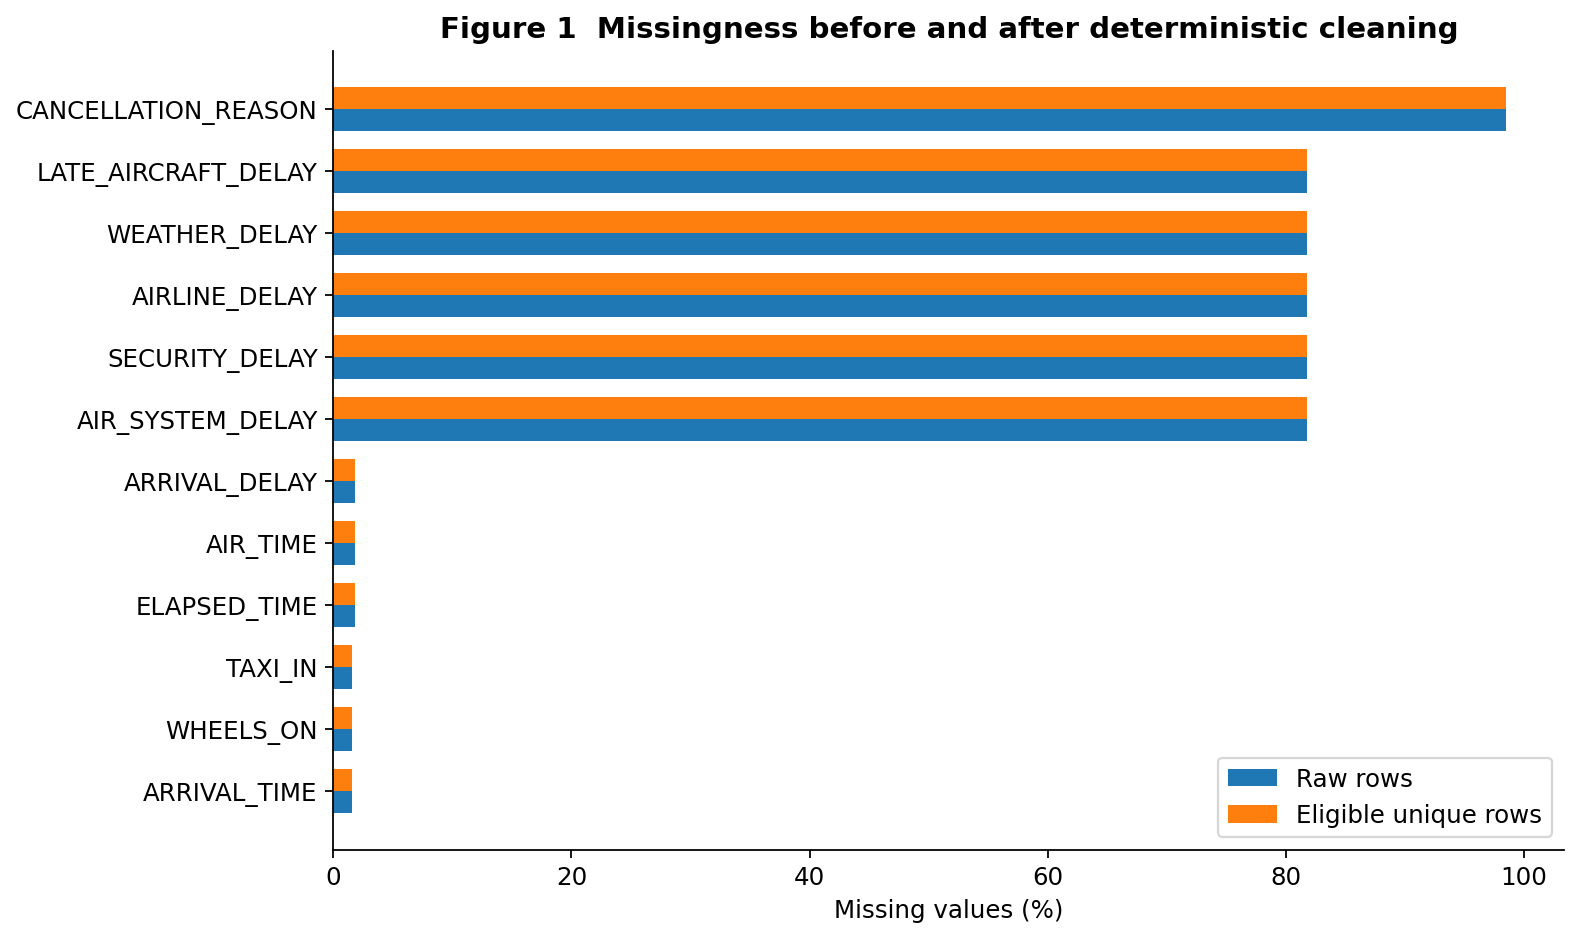

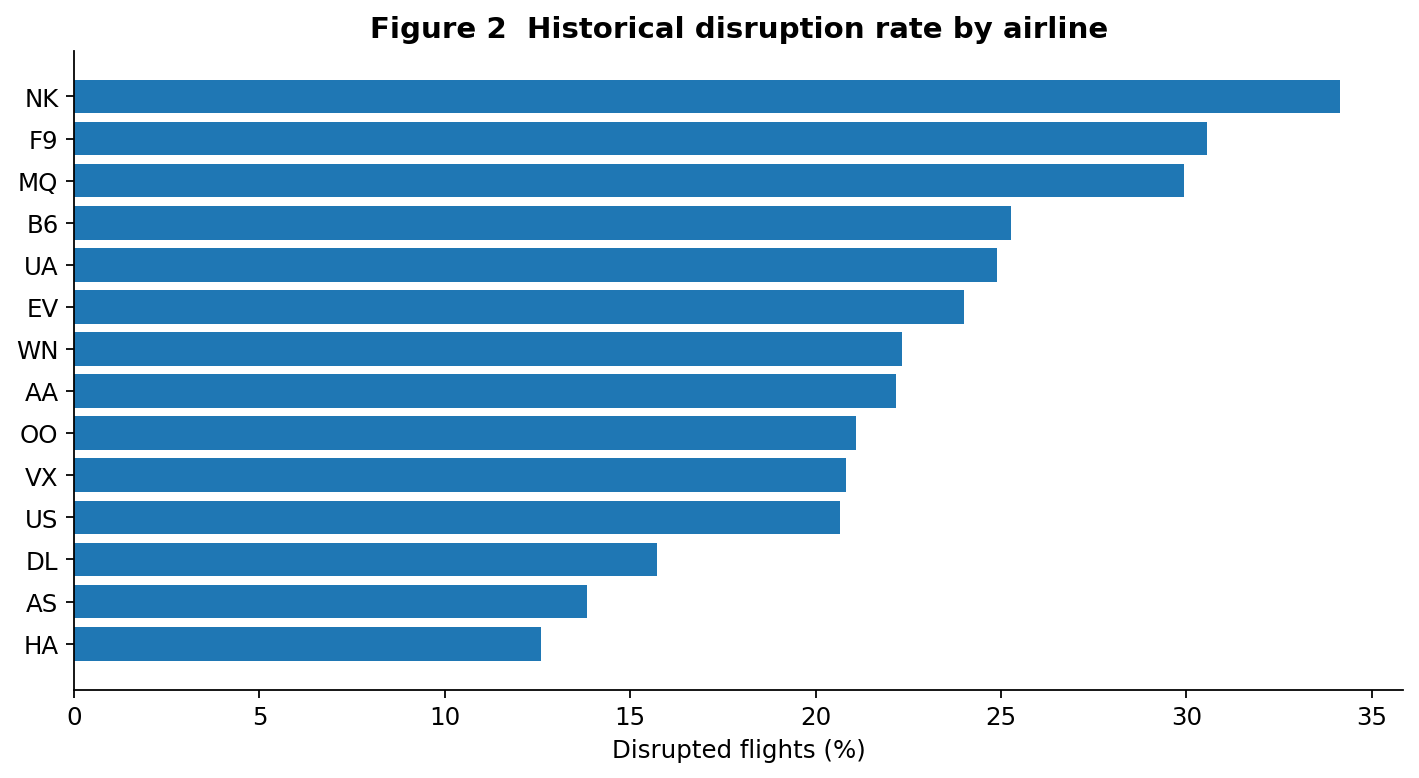

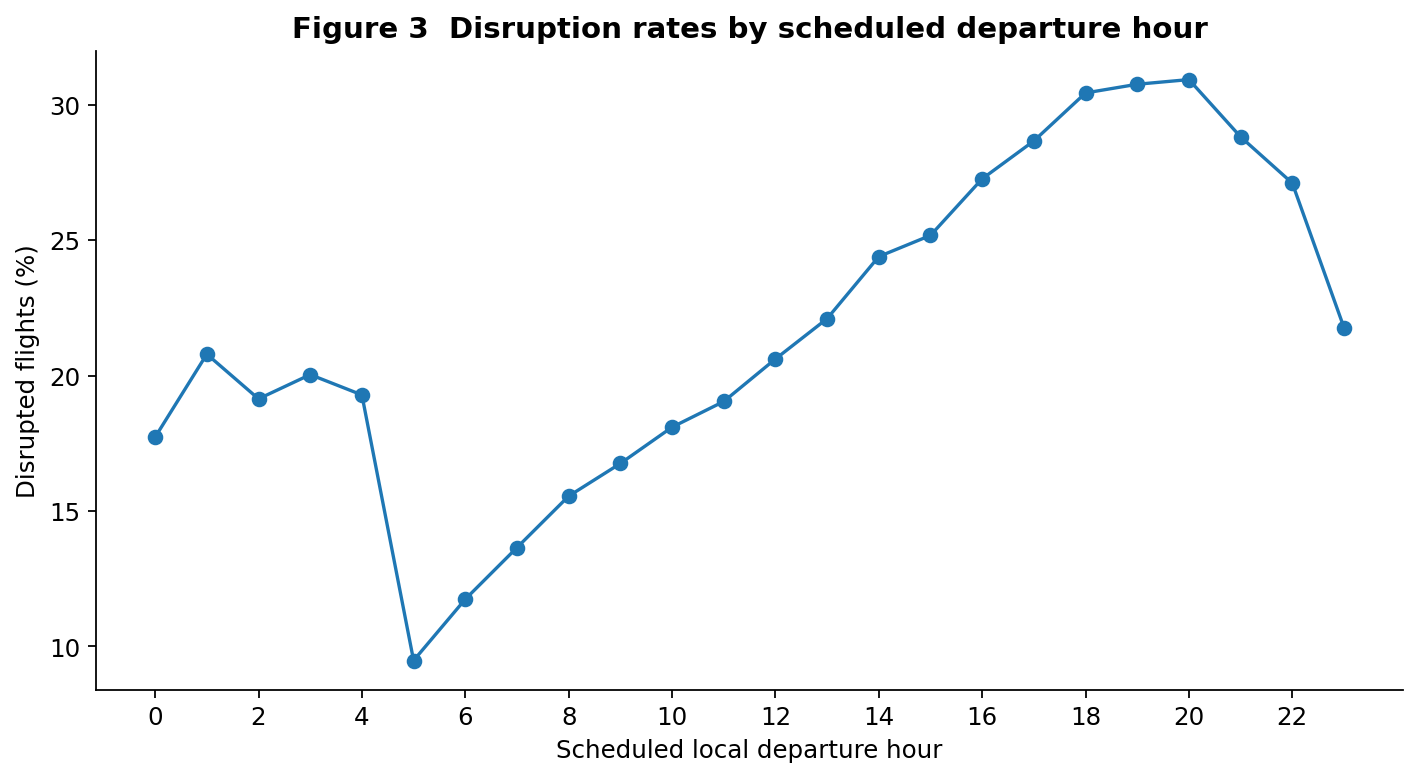

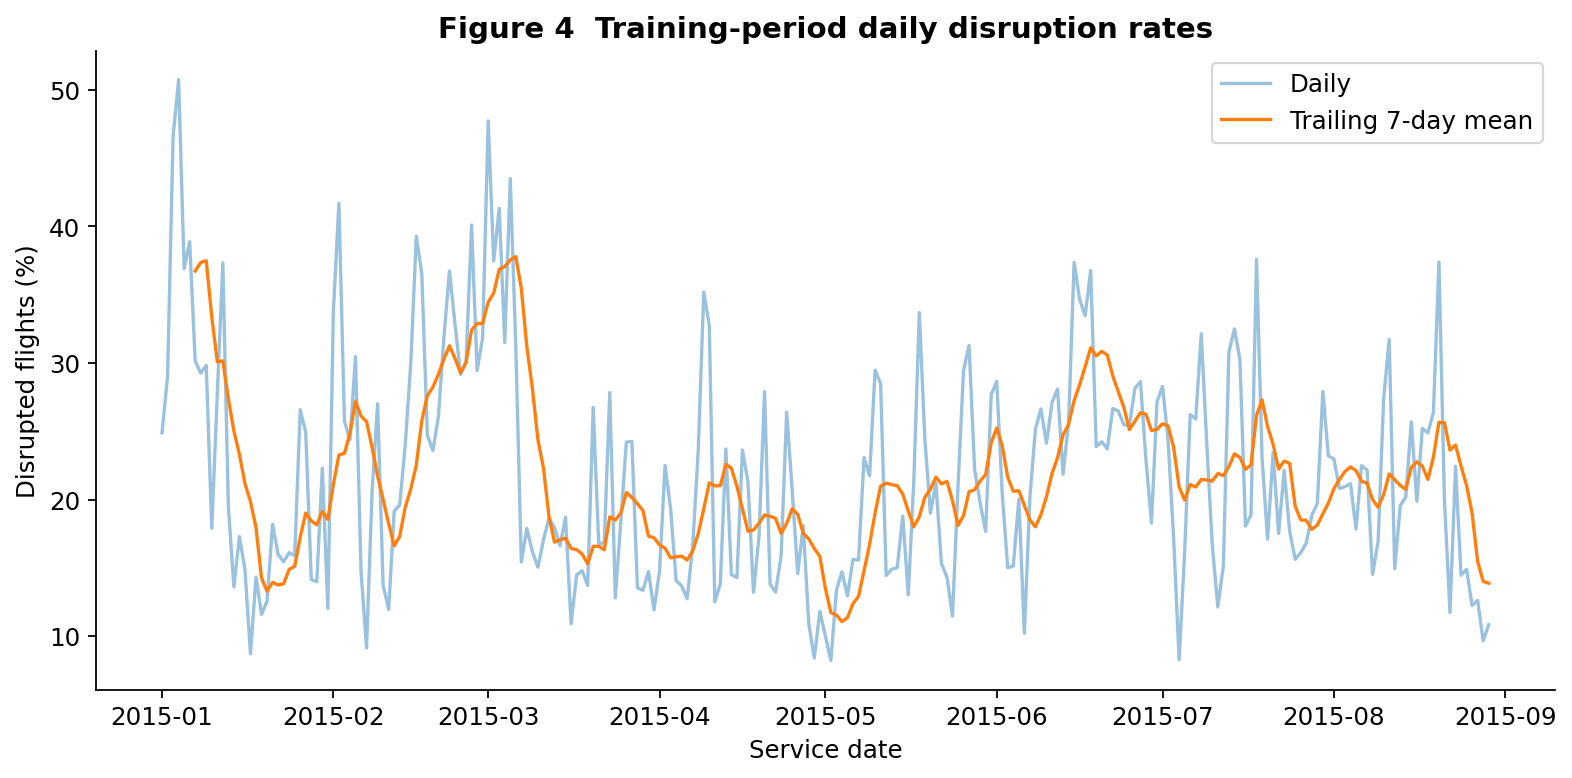

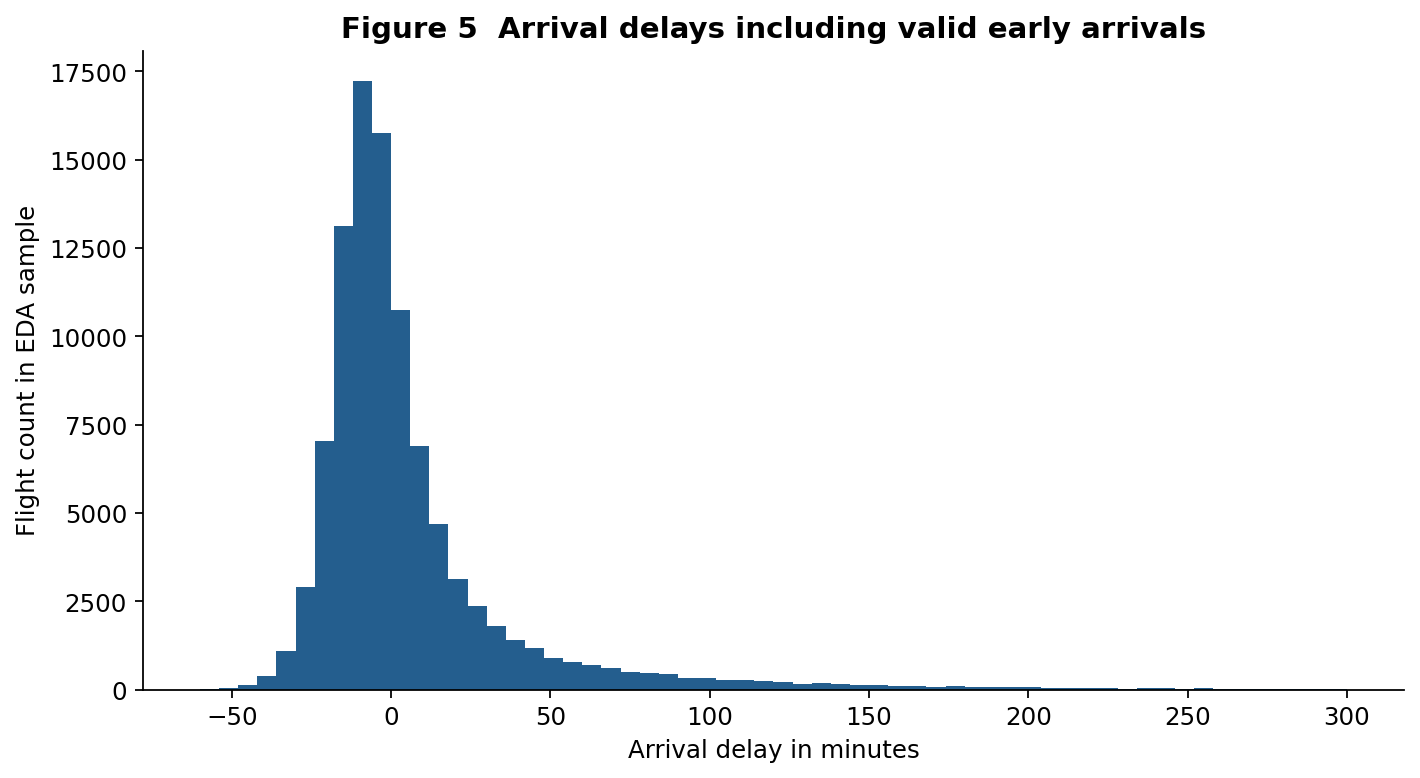

In [2]:
if not (ROOT / 'reports/figure_captions.json').exists():
    run_stage('build_visuals.py')
from IPython.display import Image, display
for item in json.loads((ROOT / 'reports/figure_captions.json').read_text())[:5]:
    display(Image(filename=str(ROOT / 'reports/figures' / item['filename'])))
    print(item['caption'])

In [3]:
display(pd.read_csv(ROOT / 'reports/outlier_review.csv'))
from src.features import make_features
sample = pd.read_csv(ROOT / 'data/processed/train.csv.gz', nrows=10)
display(make_features(sample))

,column,sample_n,q1,q3,lower_fence,upper_fence,flagged_n,decision
0,DISTANCE,100000,373.0,1060.25,-657.875,2091.125,6023,Retain domain-valid extremes; review IQR flags...
1,SCHEDULED_TIME,99999,85.0,173.00,-47.000,305.000,5110,Retain domain-valid extremes; review IQR flags...
2,ARRIVAL_DELAY,97880,-13.0,10.00,-47.500,44.500,8593,Retain domain-valid extremes; review IQR flags...
3,DEPARTURE_DELAY,98191,-5.0,9.00,-26.000,30.000,12197,Retain domain-valid extremes; review IQR flags...


,dep_minute,arr_minute,distance,scheduled_minutes,month,weekday,dep_sin,dep_cos,arr_sin,arr_cos,weekday_sin,weekday_cos,month_sin,month_cos,weekend,late_departure,log_distance,scheduled_miles_per_hour,origin_bts_id,destination_bts_id,airline,origin,destination,route
0,5.0,270.0,1448.0,205.0,1.0,3.0,0.021815,0.999762,0.923880,0.382683,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.278629,423.804878,0.0,0.0,AS,ANC,SEA,ANC_SEA
1,10.0,470.0,2330.0,280.0,1.0,3.0,0.043619,0.999048,0.887011,-0.461749,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.754053,499.285714,0.0,0.0,AA,LAX,PBI,LAX_PBI
2,20.0,486.0,2296.0,286.0,1.0,3.0,0.087156,0.996195,0.852640,-0.522499,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.739359,481.678322,0.0,0.0,US,SFO,CLT,SFO_CLT
3,20.0,485.0,2342.0,285.0,1.0,3.0,0.087156,0.996195,0.854912,-0.518773,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.759187,493.052632,0.0,0.0,AA,LAX,MIA,LAX_MIA
4,25.0,200.0,1448.0,235.0,1.0,3.0,0.108867,0.994056,0.766044,0.642788,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.278629,369.702128,0.0,0.0,AS,SEA,ANC,SEA_ANC
5,25.0,362.0,1589.0,217.0,1.0,3.0,0.108867,0.994056,0.999962,-0.008727,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.371489,439.354839,0.0,0.0,DL,SFO,MSP,SFO_MSP
6,25.0,326.0,1299.0,181.0,1.0,3.0,0.108867,0.994056,0.989016,0.147809,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.170120,430.607735,0.0,0.0,NK,LAS,MSP,LAS_MSP
7,30.0,483.0,2125.0,273.0,1.0,3.0,0.130526,0.991445,0.859406,-0.511293,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.661998,467.032967,0.0,0.0,US,LAX,CLT,LAX_CLT
8,30.0,345.0,1464.0,195.0,1.0,3.0,0.130526,0.991445,0.997859,0.065403,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.289611,450.461538,0.0,0.0,AA,SFO,DFW,SFO_DFW
9,30.0,431.0,1747.0,221.0,1.0,3.0,0.130526,0.991445,0.952396,-0.304864,0.433884,-0.900969,0.0,1.0,0.0,0.0,7.466228,474.298643,0.0,0.0,DL,LAS,ATL,LAS_ATL


## Feature-value check

A plausible feature is not automatically useful. The next notebook compares base and extended features using the same model settings and temporal folds. The completed ablation selected the base set: extended-minus-base mean AP was −0.000386. That small observed difference does not establish strong superiority.

The scheduled-speed proxy is based on gate-to-gate duration, not measured airspeed. No live weather, holiday signal or actual delay is introduced. Continue to **04_models_and_tuning.ipynb**, keeping the test outcomes outside feature development.
